<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Survey Dataset Preview (First 5 Employees) ===
   Q1_Salary_Fairness  Q2_Bonus_Benefits  Q3_Pay_Transparency  \
0                   4                  3                    4   
1                   3                  3                    3   
2                   4                  4                    3   
3                   5                  4                    4   
4                   3                  3                    3   

   Q4_Manager_Support  Q5_Team_Spirit  Q6_Work_Environment  Q7_Career_Growth  \
0                   3               3                    2                 4   
1                   3               2                    3                 3   
2                   3               3                    3                 5   
3                   3               4                    3                 4   
4                   2               2                    4                 3   

   Q8_Skill_Training  Q9_Workload_Balance  Q10_Role_Clarity  
0              

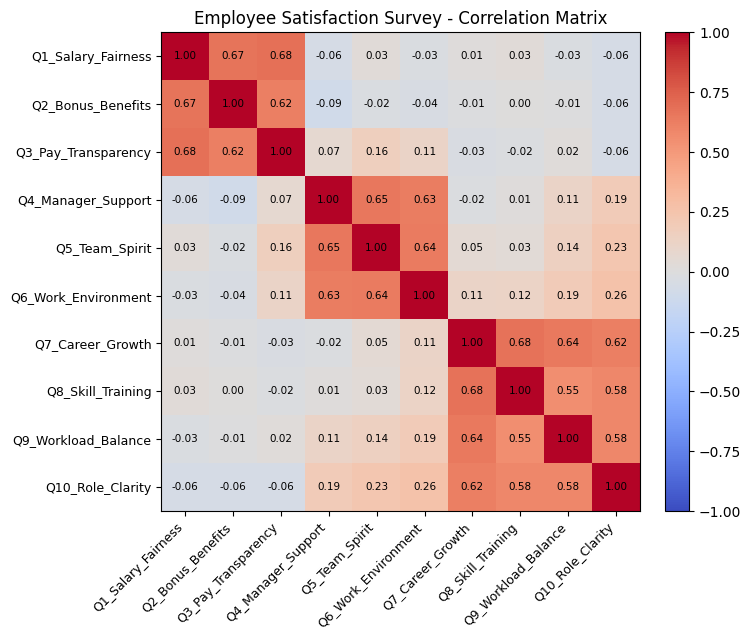

=== Task 2: FactorAnalysis Log-Likelihood & Avg Noise Variance ===
Factors = 2 | Avg Log-Likelihood: -12.5853 | Mean Noise Variance: 0.5475
Factors = 3 | Avg Log-Likelihood: -11.9049 | Mean Noise Variance: 0.3539
Factors = 4 | Avg Log-Likelihood: -11.8941 | Mean Noise Variance: 0.3369

=== Task 3: Varimax-Rotated Factor Loadings (3 Factors) ===
                     Factor 1  Factor 2  Factor 3
Q1_Salary_Fairness      0.007     0.853    -0.037
Q2_Bonus_Benefits      -0.007     0.777    -0.074
Q3_Pay_Transparency    -0.033     0.809     0.138
Q4_Manager_Support      0.006    -0.042     0.812
Q5_Team_Spirit          0.063     0.060     0.813
Q6_Work_Environment     0.142     0.010     0.770
Q7_Career_Growth        0.865     0.000    -0.019
Q8_Skill_Training       0.778     0.013     0.000
Q9_Workload_Balance     0.736    -0.001     0.126
Q10_Role_Clarity        0.736    -0.065     0.223


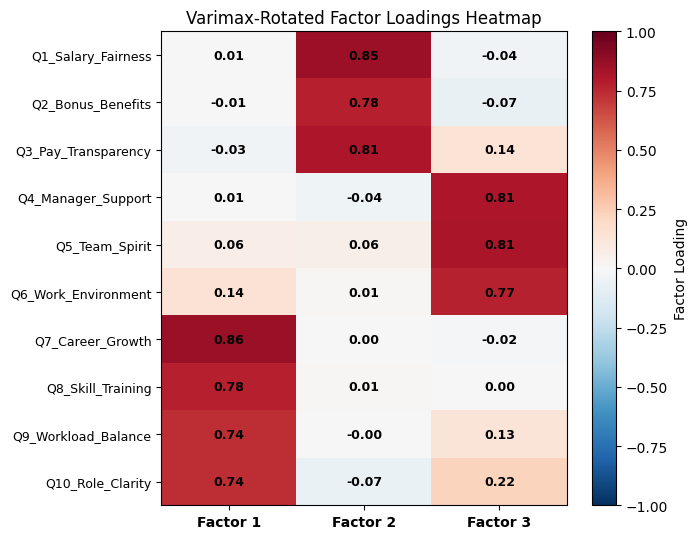


=== Task 4: Latent Factor Interpretation (|Loading| >= 0.50) ===
Factor 1 -> Suggested Name: 'Career Growth & Workload'
   High-loading questions: ['Q7_Career_Growth', 'Q8_Skill_Training', 'Q9_Workload_Balance', 'Q10_Role_Clarity']
Factor 2 -> Suggested Name: 'Compensation & Benefits'
   High-loading questions: ['Q1_Salary_Fairness', 'Q2_Bonus_Benefits', 'Q3_Pay_Transparency']
Factor 3 -> Suggested Name: 'Work Culture & Support'
   High-loading questions: ['Q4_Manager_Support', 'Q5_Team_Spirit', 'Q6_Work_Environment']

=== Task 5: Factor Analysis vs PCA Comparison ===
PCA Total Explained Variance (3 PCs): 75.05%
FA  Total Common Variance (3 Factors): 64.61%

                     FA Communality  FA Uniqueness (Noise)  \
Q1_Salary_Fairness            0.729                  0.272   
Q2_Bonus_Benefits             0.609                  0.390   
Q3_Pay_Transparency           0.675                  0.325   
Q4_Manager_Support            0.662                  0.339   
Q5_Team_Spirit        

/tmp/ipykernel_387/3737627991.py:167: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


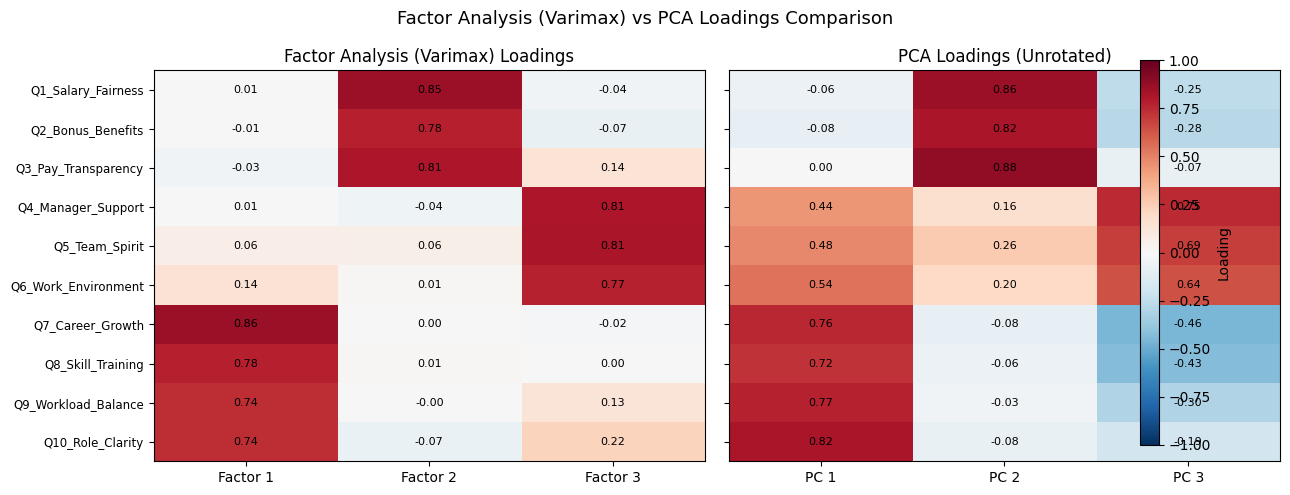

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA

# Reproducibility
np.random.seed(42)

# ==========================================
# Task 1: Generate, Load & Explore Survey Data (300 Employees, 10 Questions, Likert 1-5)
# ==========================================
n_employees = 300

# 3 true underlying latent factors
f_comp = np.random.normal(0, 1, n_employees)     # Compensation
f_culture = np.random.normal(0, 1, n_employees)  # Work Culture
f_growth = np.random.normal(0, 1, n_employees)   # Career Growth & Workload

def to_likert(signal, noise_std=0.45):
    raw = 3.0 + 0.85 * signal + np.random.normal(0, noise_std, len(signal))
    return np.clip(np.rint(raw), 1, 5).astype(int)

df = pd.DataFrame({
    "Q1_Salary_Fairness":   to_likert(0.9 * f_comp),
    "Q2_Bonus_Benefits":    to_likert(0.85 * f_comp),
    "Q3_Pay_Transparency":  to_likert(0.8 * f_comp + 0.15 * f_culture),
    "Q4_Manager_Support":   to_likert(0.9 * f_culture),
    "Q5_Team_Spirit":       to_likert(0.85 * f_culture),
    "Q6_Work_Environment":  to_likert(0.8 * f_culture + 0.1 * f_growth),
    "Q7_Career_Growth":     to_likert(0.9 * f_growth),
    "Q8_Skill_Training":    to_likert(0.85 * f_growth),
    "Q9_Workload_Balance":  to_likert(0.75 * f_growth + 0.2 * f_culture),
    "Q10_Role_Clarity":     to_likert(0.7 * f_growth + 0.25 * f_culture),
})

print("=== Survey Dataset Preview (First 5 Employees) ===")
print(df.head(), "\n")
print("=== Summary Statistics ===")
print(df.describe().T[["mean", "std", "min", "max"]].round(2), "\n")

# Check correlation matrix
corr = df.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(df.columns)))
ax.set_yticks(range(len(df.columns)))
ax.set_xticklabels(df.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(df.columns, fontsize=9)
for i in range(len(df.columns)):
    for j in range(len(df.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Employee Satisfaction Survey - Correlation Matrix")
plt.tight_layout()
plt.show()

# Standardise survey responses
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# ==========================================
# Task 2: Fit Scikit-learn FactorAnalysis with 2, 3, and 4 Factors
# ==========================================
print("=== Task 2: FactorAnalysis Log-Likelihood & Avg Noise Variance ===")
fa_models = {}
for k in [2, 3, 4]:
    fa = FactorAnalysis(n_components=k, random_state=42)
    fa.fit(X_scaled)
    fa_models[k] = fa
    print(f"Factors = {k} | Avg Log-Likelihood: {fa.score(X_scaled):.4f} | Mean Noise Variance: {fa.noise_variance_.mean():.4f}")

# ==========================================
# Task 3: Apply Varimax Rotation (k=3) & Display Loadings Heatmap
# ==========================================
fa_varimax = FactorAnalysis(n_components=3, rotation="varimax", random_state=42)
fa_varimax.fit(X_scaled)

# Loadings matrix: shape (10 questions x 3 factors)
loadings = pd.DataFrame(
    fa_varimax.components_.T,
    index=df.columns,
    columns=["Factor 1", "Factor 2", "Factor 3"]
)

print("\n=== Task 3: Varimax-Rotated Factor Loadings (3 Factors) ===")
print(loadings.round(3))

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(loadings.shape[1]))
ax.set_yticks(range(loadings.shape[0]))
ax.set_xticklabels(loadings.columns, fontsize=10, fontweight="bold")
ax.set_yticklabels(loadings.index, fontsize=9)
for i in range(loadings.shape[0]):
    for j in range(loadings.shape[1]):
        ax.text(j, i, f"{loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, fontweight="bold")
plt.colorbar(im, ax=ax, label="Factor Loading")
ax.set_title("Varimax-Rotated Factor Loadings Heatmap")
plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Name Each Factor from High-Loading Questions
# ==========================================
print("\n=== Task 4: Latent Factor Interpretation (|Loading| >= 0.50) ===")
for col in loadings.columns:
    high_q = loadings.index[loadings[col].abs() >= 0.50].tolist()
    # Suggest descriptive name based on dominant questions
    q_str = " ".join(high_q)
    if "Salary" in q_str or "Bonus" in q_str:
        suggested_name = "Compensation & Benefits"
    elif "Manager" in q_str or "Team" in q_str:
        suggested_name = "Work Culture & Support"
    else:
        suggested_name = "Career Growth & Workload"
    print(f"{col} -> Suggested Name: '{suggested_name}'")
    print(f"   High-loading questions: {high_q}")

# ==========================================
# Task 5: Compare Factor Analysis vs PCA on the Same Data
# ==========================================
pca = PCA(n_components=3, random_state=42)
pca.fit(X_scaled)

# PCA loadings = eigenvectors * sqrt(eigenvalues)
pca_loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=df.columns,
    columns=["PC 1", "PC 2", "PC 3"]
)

# Communalities (variance explained per question by the 3 components/factors)
fa_communality = np.sum(loadings.values ** 2, axis=1)
pca_communality = np.sum(pca_loadings.values ** 2, axis=1)

comp_df = pd.DataFrame({
    "FA Communality": np.round(fa_communality, 3),
    "FA Uniqueness (Noise)": np.round(fa_varimax.noise_variance_, 3),
    "PCA Variance Captured": np.round(pca_communality, 3)
}, index=df.columns)

print("\n=== Task 5: Factor Analysis vs PCA Comparison ===")
print(f"PCA Total Explained Variance (3 PCs): {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"FA  Total Common Variance (3 Factors): {fa_communality.sum() / len(df.columns) * 100:.2f}%\n")
print(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im0 = axes[0].imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axes[0].set_title("Factor Analysis (Varimax) Loadings")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(loadings.columns)
axes[0].set_yticks(range(len(df.columns))); axes[0].set_yticklabels(df.columns, fontsize=8.5)
for i in range(len(df.columns)):
    for j in range(3):
        axes[0].text(j, i, f"{loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

im1 = axes[1].imshow(pca_loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axes[1].set_title("PCA Loadings (Unrotated)")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(pca_loadings.columns)
axes[1].set_yticks(range(len(df.columns))); axes[1].set_yticklabels([""] * len(df.columns))
for i in range(len(df.columns)):
    for j in range(3):
        axes[1].text(j, i, f"{pca_loadings.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im1, ax=axes, fraction=0.025, pad=0.02, label="Loading")
plt.suptitle("Factor Analysis (Varimax) vs PCA Loadings Comparison", fontsize=13)
plt.tight_layout()
plt.show()